In [3]:
%matplotlib inline
%load_ext autoreload
%autoreload 2
import matplotlib
import matplotlib.pyplot as plt
import sigpy as sp
import pandas as pd
import sigpy.plot as pl
import numpy as np
import os
import sys
from pathlib import Path
import jax as jx
import time
import h5py


sys.path.insert(0,'/Users/ayman/Desktop/MSc Project Local/MSc-Project-ZTE')
import aymansigmri as asm

sys.path.insert(0, "/Users/ayman/Documents/GitHub/riesling/python")

import riesling as rlp


riesling_bin = Path.home() / "Documents" / "github" / "riesling" / "build" / "cxx" / "riesling"
os.environ["PATH"] += os.pathsep + str(riesling_bin)

save_dir = "/Users/ayman/Desktop/LowRank/Data Saved"

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


## UTE

In [8]:
hires_zte = '/Users/ayman/Desktop/LowRank/Data Saved/Phantom/zte'
coorhires_zte = rlp.io.read_trajectory(f'{hires_zte}.h5')
coorhires_zte = np.asarray(coorhires_zte)
kspacehires_zte = rlp.io.read_data(f'{hires_zte}.h5')
kspacehires_zte = np.asarray(kspacehires_zte)
kspacehires_zte = kspacehires_zte[0, 0] 
kspacehires_zte = np.moveaxis(kspacehires_zte, -1, 0)


print(coorhires_zte.shape)
print(kspacehires_zte.shape)

(65278, 248, 3)
(16, 65278, 248)


In [7]:
zte = '/Users/ayman/Desktop/LowRank/Data Saved/Phantom/zte'
ute = '/Users/ayman/Desktop/LowRank/Data Saved/Phantom/ute'

#!riesling op-nufft "{ute}.h5" "{ute}-nufft.h5" -v2
#!riesling op-nufft "{zte}.h5" "{zte}-nufft.h5" -v2

In [ ]:
zte_im, traj = asm.h5tonum(f'{zte}-nufft.h5', showshape=True)
riesling_cartksp_zte = sp.fft(zte_im)

ute_im, traj = asm.h5tonum(f'{ute}-nufft.h5', showshape=True)
riesling_cartksp_ute = sp.fft(ute_im)

(16, 252, 252, 252)
(3, 65278, 248)
(16, 252, 252, 252)
(3, 64512, 280)


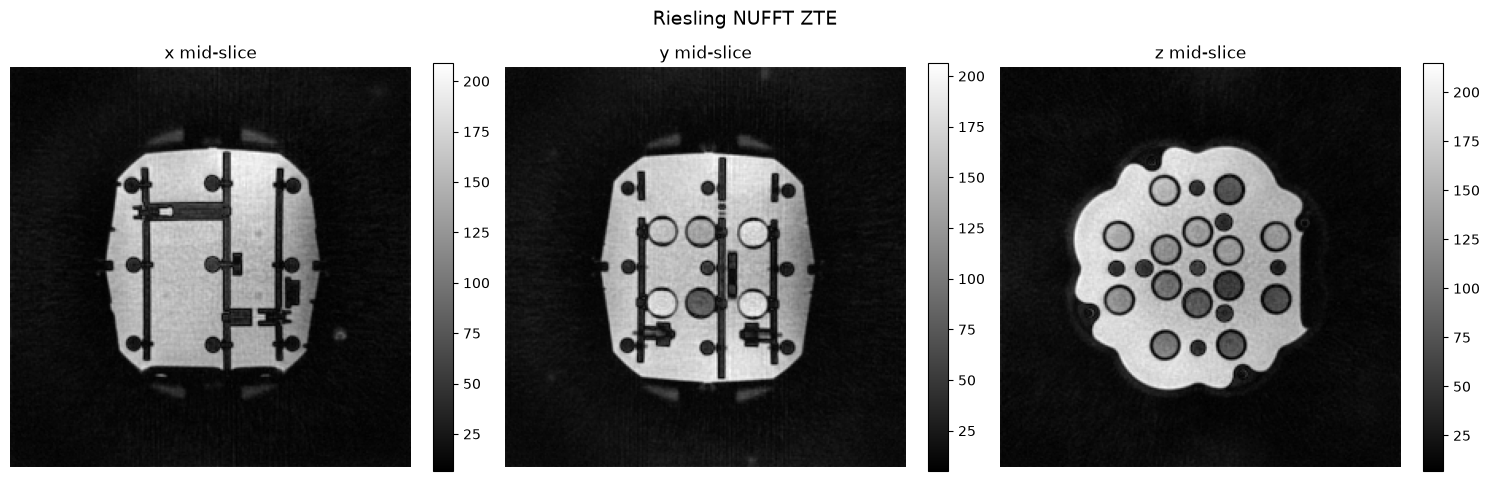

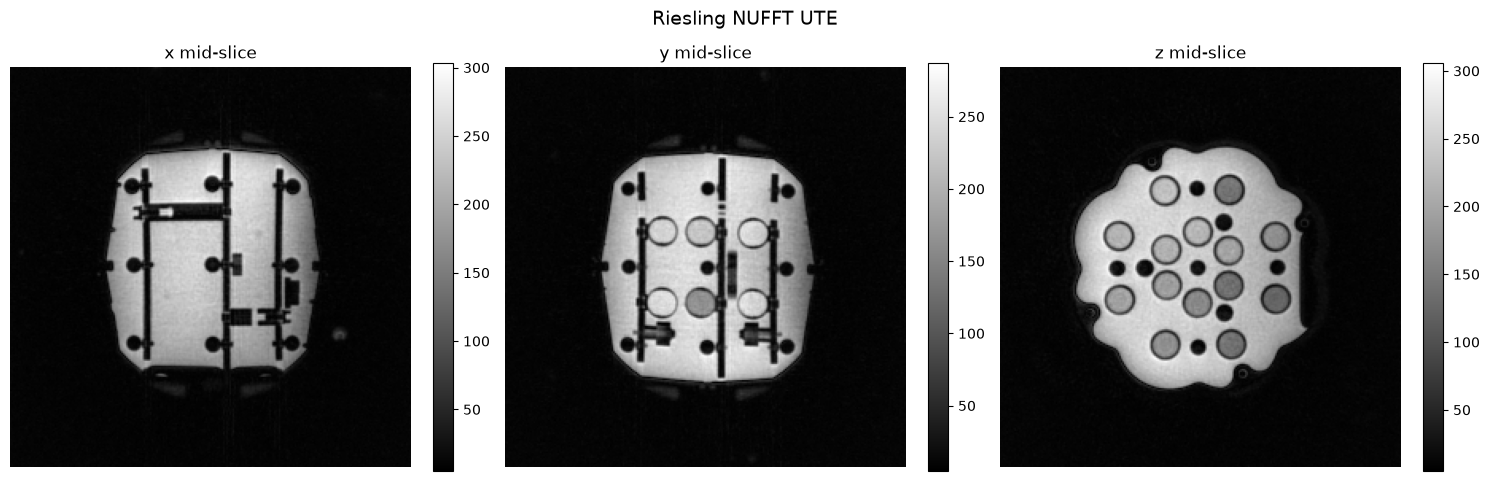

In [6]:
asm.plot_planes(zte_im, title='Riesling NUFFT ZTE', inputtype_kspace=False)
asm.plot_planes(ute_im, title='Riesling NUFFT UTE', inputtype_kspace=False)

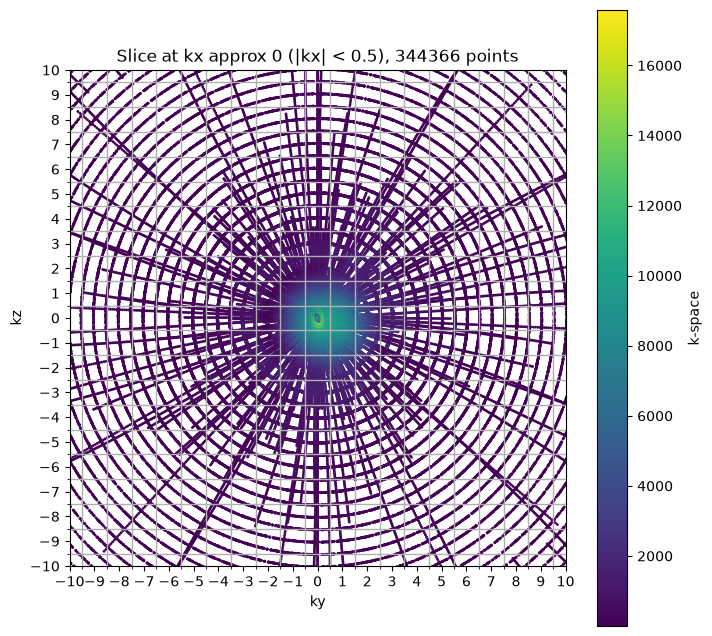

In [14]:
all_ztecoords = coorhires_zte.reshape(-1, 3)
all_zteksp = np.abs(kspacehires_zte[0]).reshape(-1)   # coil 0

tol = 0.5   # slab half-thickness in kx
maskztevis = np.abs(all_ztecoords[:, 0]) < tol

fig, ax = plt.subplots(figsize=(8, 8))
im = ax.scatter(
    all_ztecoords[maskztevis, 1], all_ztecoords[maskztevis, 2],
    c=all_zteksp[maskztevis],
    s=1
)
ax.set_title(f'Slice at kx approx 0 (|kx| < {tol}), {maskztevis.sum()} points')
ax.set_xlabel('ky')
ax.set_ylabel('kz')
ax.set_aspect('equal')
ax.xaxis.set_major_locator(plt.MultipleLocator(1))
ax.yaxis.set_major_locator(plt.MultipleLocator(1))
ax.xaxis.set_minor_locator(plt.MultipleLocator(1, offset=0.5))
ax.yaxis.set_minor_locator(plt.MultipleLocator(1, offset=0.5))
ax.grid(visible=True, which='minor', linewidth=1)
ax.set_xlim(-10, 10)
ax.set_ylim(-10, 10)
fig.colorbar(im, ax=ax, label='k-space')
plt.show()
